<a href="https://colab.research.google.com/github/Lourdes-Churacutipa/Repositorio-de-lourdes/blob/main/Lab9_2_CNN_Peru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Redes Neuronales Convolucionales (CNN)
## Ciencia de Datos Ambientales – Aplicado al Perú

**Duración:** 75 minutos

Referencia: [Deep Learning book (Goodfellow et al.)](https://www.deeplearningbook.org/) | [Keras](https://keras.io/)

---

### Objetivos de aprendizaje

1. Distinguir entre características diseñadas manualmente y características aprendidas.
2. Representar imágenes y datos multicanal como tensores.
3. Describir las operaciones clave de las CNN: convolución, pooling y ReLU.
4. Explicar el patrón encoder-decoder que subyace a las arquitecturas CNN.
5. Construir y entrenar una CNN en Keras para clasificación de imágenes satelitales.

## 1. ¿Qué es una Característica?

En todos los Labs anteriores, las **características ya estaban preparadas** para nosotros: NDVI, temperatura, precipitación, bandas espectrales. Alguien decidió qué medir, y los números llegaron en una hoja de cálculo.

Pero, ¿qué pasa con los datos no estructurados?

### Ejemplo: Clasificar imágenes de drones del SERNANP

El SERNANP usa drones para monitorear la deforestación en el Manu. Quieres clasificar cada imagen como "bosque intacto", "bosque degradado" o "deforestado".

¿Puedes escribir una fórmula para "bosque intacto"?
- "¿Blobs verdes?" → falla si hay sombras o luz directa
- "¿Forma de copa arbórea?" → ¿cómo codificas "forma" como número?

No hay un vector de características limpio que capture "bosque-ness". Aquí es donde las CNN son poderosas.

### Características diseñadas vs. características aprendidas

| Enfoque | Las características vienen de | Ejemplo |
|---------|------------------------------|--------|
| ML clásico | *Tú* — conocimiento de dominio, prueba y error | Calcular NDVI desde bandas Landsat, luego alimentar a Random Forest |
| Deep Learning (CNN) | *La red* — aprendidas automáticamente durante el entrenamiento | Alimentar bandas brutas a una CNN; descubre que las combinaciones "NDVI-like" son útiles |

Las CNN fusionan extracción de características y modelado — optimizados juntos de extremo a extremo.

## 2. Tensores: Cómo Representamos los Datos

Las CNN trabajan con **tensores** — la generalización de escalares, vectores y matrices.

| Nombre | Dimensiones | Ejemplo |
|--------|-------------|---------|
| Escalar | 0D | Temperatura: `25.3` |
| Vector | 1D | Características de una estación: `[temp, precip, humedad]` |
| Matriz | 2D | Dataset tabular: filas×columnas |
| **Tensor 3D** | **3D** | **Una imagen: alto×ancho×canales** |
| Tensor 4D | 4D | Lote de imágenes: lote×alto×ancho×canales |

### Imágenes satelitales como tensores

Un parche Landsat de 64×64 pixeles con 6 bandas espectrales = tensor de forma `(64, 64, 6)`

Esto contiene $64 \times 64 \times 6 = 24{,}576$ números — estos son los valores brutos que la CNN procesará.

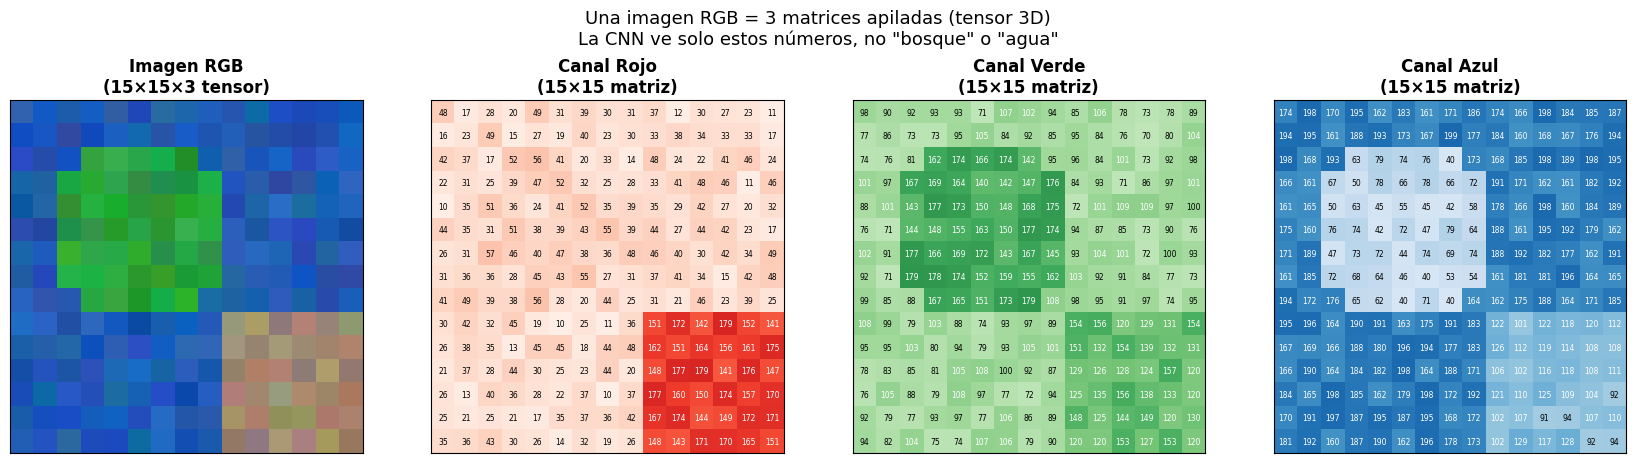

Forma del tensor de imagen: (15, 15, 3)  (alto, ancho, canales)
Total de números: 675 valores de 0-255


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Demostrar cómo una imagen de cobertura del suelo es un tensor 3D
np.random.seed(42)

# Simular una imagen RGB pequeña de una parcela en la Amazonia
img = np.zeros((15, 15, 3), dtype=np.uint8)
# Bosque verde
for i in range(15):
    for j in range(15):
        if (i-5)**2 + (j-5)**2 < 15:
            img[i,j] = [40, 160, 60]   # verde bosque
        elif i > 8 and j > 8:
            img[i,j] = [160, 140, 110]  # marrón suelo/quemado
        else:
            img[i,j] = [30, 90, 180]    # azul agua

# Añadir ruido
img = np.clip(img + np.random.randint(-20, 20, img.shape), 0, 255).astype(np.uint8)

fig, ejes = plt.subplots(1, 4, figsize=(17, 4.5))

ejes[0].imshow(img)
ejes[0].set_title('Imagen RGB\n(15×15×3 tensor)', fontweight='bold')
ejes[0].set_xticks([]); ejes[0].set_yticks([])

nombres_canal = ['Canal Rojo', 'Canal Verde', 'Canal Azul']
cmaps_canal   = ['Reds', 'Greens', 'Blues']
for i, (nombre, cmap) in enumerate(zip(nombres_canal, cmaps_canal)):
    ax = ejes[i+1]
    ax.imshow(img[:, :, i], cmap=cmap, vmin=0, vmax=255)
    for r in range(15):
        for c in range(15):
            ax.text(c, r, str(img[r, c, i]), ha='center', va='center',
                    fontsize=5.5, color='white' if img[r,c,i] > 100 else 'black')
    ax.set_title(f'{nombre}\n(15×15 matriz)', fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle('Una imagen RGB = 3 matrices apiladas (tensor 3D)\n'
             'La CNN ve solo estos números, no "bosque" o "agua"',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(f"Forma del tensor de imagen: {img.shape}  (alto, ancho, canales)")
print(f"Total de números: {img.size:,} valores de 0-255")

## 3. Redes Neuronales Profundas como Jerarquías de Representación

Las CNN aprenden características de forma jerárquica:

| Capa | Escala | Qué detecta en imágenes satelitales peruanas |
|------|--------|-----------------------------------------|
| Capa 1 | Píxeles individuales | Diferencias de reflectancia, bordes |
| Capa 2 | Parches ~10m | Rugosidad del dosel, suavidad del agua |
| Capa 3 | Parches ~30m | Copas de árboles, surcos agrícolas, bordes de edificios |
| Capas profundas | Región completa | Clase de cobertura, tipo de hábitat |

**Nadie programa estas características — la red las descubre de los datos.**

## 4. El Patrón Encoder-Decoder

Casi todas las arquitecturas CNN pueden entenderse como:

```
Imagen de entrada → [ENCODER] → representación compacta → [DECODER] → salida
  (alto-dim)        (capas conv)    (vector latente)       (capas densas)  (clasificación)
```

El **encoder** comprime la imagen en una representación abstracta. El **decoder** usa esa representación para producir la salida deseada.

## 5. La Operación de Convolución

Una **convolución** es una ventana deslizante pequeña — llamada **filtro** o **kernel** — que se mueve por la imagen. En cada posición, calcula la suma ponderada de los píxeles que cubre.

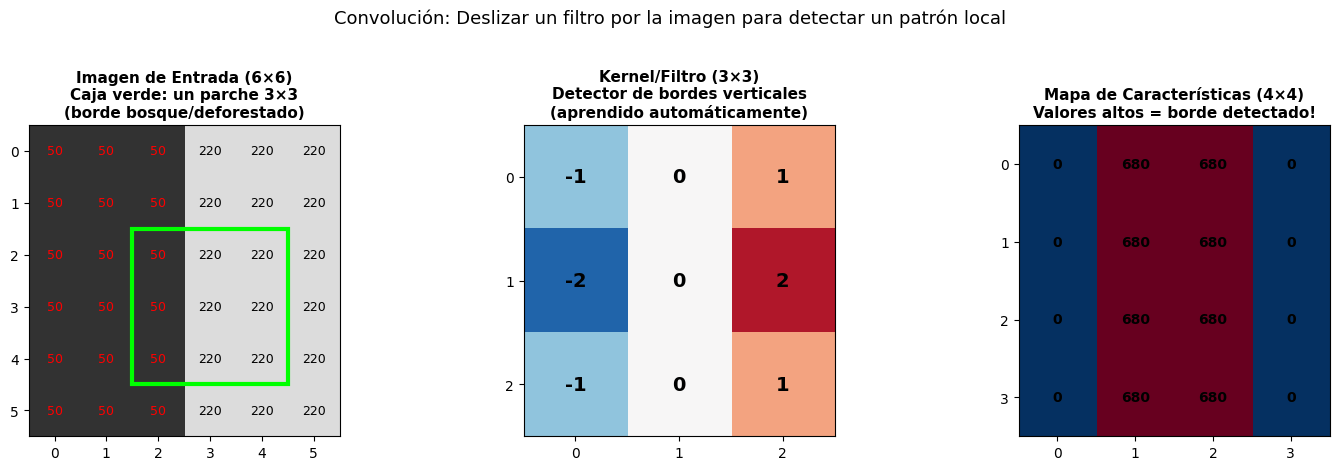

El mapa de características muestra DÓNDE el filtro respondió fuertemente.
La columna 3 (borde bosque/deforestación) tiene los valores más altos.

En una CNN REAL, los valores del filtro se APRENDEN automáticamente
a través del entrenamiento (retropropagación).


In [ ]:
# Demostrar la operación de convolución con un detector de bordes
from matplotlib.patches import Rectangle

# Imagen 6x6 con un borde vertical claro (simula borde bosque/deforestación)
imagen_borde = np.array([
    [50,  50,  50, 220, 220, 220],
    [50,  50,  50, 220, 220, 220],
    [50,  50,  50, 220, 220, 220],
    [50,  50,  50, 220, 220, 220],
    [50,  50,  50, 220, 220, 220],
    [50,  50,  50, 220, 220, 220],
], dtype=float)

# Kernel detector de bordes verticales (tipo Sobel)
kernel = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)

# Convolución manual
def conv2d(img, k):
    kh, kw = k.shape
    ih, iw = img.shape
    out = np.zeros((ih - kh + 1, iw - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i, j] = (img[i:i+kh, j:j+kw] * k).sum()
    return out

mapa_caracteristicas = conv2d(imagen_borde, kernel)

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))

# Imagen de entrada
ejes[0].imshow(imagen_borde, cmap='gray', vmin=0, vmax=255)
for i in range(6):
    for j in range(6):
        ejes[0].text(j, i, int(imagen_borde[i,j]), ha='center', va='center',
                     color='red' if imagen_borde[i,j] < 130 else 'black', fontsize=9)
rect = Rectangle((1.5, 1.5), 3, 3, fill=False, edgecolor='lime', linewidth=3)
ejes[0].add_patch(rect)
ejes[0].set_title('Imagen de Entrada (6×6)\nCaja verde: un parche 3×3\n(borde bosque/deforestado)',
                   fontsize=11, fontweight='bold')
ejes[0].set_xticks(range(6)); ejes[0].set_yticks(range(6))

# Kernel
ejes[1].imshow(kernel, cmap='RdBu_r', vmin=-2.5, vmax=2.5)
for i in range(3):
    for j in range(3):
        ejes[1].text(j, i, int(kernel[i,j]), ha='center', va='center',
                     fontsize=14, fontweight='bold')
ejes[1].set_title('Kernel/Filtro (3×3)\nDetector de bordes verticales\n(aprendido automáticamente)',
                   fontsize=11, fontweight='bold')
ejes[1].set_xticks(range(3)); ejes[1].set_yticks(range(3))

# Mapa de características
ejes[2].imshow(mapa_caracteristicas, cmap='RdBu_r')
for i in range(mapa_caracteristicas.shape[0]):
    for j in range(mapa_caracteristicas.shape[1]):
        ejes[2].text(j, i, f'{int(mapa_caracteristicas[i,j])}',
                     ha='center', va='center', fontsize=10, fontweight='bold')
ejes[2].set_title(f'Mapa de Características ({mapa_caracteristicas.shape[0]}×{mapa_caracteristicas.shape[1]})\n'
                   'Valores altos = borde detectado!', fontsize=11, fontweight='bold')
ejes[2].set_xticks(range(mapa_caracteristicas.shape[1]))
ejes[2].set_yticks(range(mapa_caracteristicas.shape[0]))

plt.suptitle('Convolución: Deslizar un filtro por la imagen para detectar un patrón local',
             fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

print("El mapa de características muestra DÓNDE el filtro respondió fuertemente.")
print("La columna 3 (borde bosque/deforestación) tiene los valores más altos.")
print("\nEn una CNN REAL, los valores del filtro se APRENDEN automáticamente")
print("a través del entrenamiento (retropropagación).")

### Max Pooling: Reducir el Tamaño Espacial

Después de una capa convolucional, el **max pooling** reduce las dimensiones espaciales seleccionando el valor máximo en cada bloque 2×2:
- **Reduce el cómputo** en un factor de 4×
- **Proporciona invarianza a la translación** — pequeños desplazamientos en la entrada no cambian mucho la salida

## 6. Construir una CNN en Keras

Arquitectura CNN para clasificación de imágenes satelitales:

```
[Conv(32) → ReLU → Pool]   → Detectar patrones de bajo nivel (bordes, colores)
[Conv(64) → ReLU → Pool]   → Detectar patrones de nivel medio (texturas, formas)
[Flatten]                   → Vectorizar el mapa de características
[Dense(128) → ReLU]         → Clasificar a partir de la representación aprendida
[Dense(10) → Softmax]       → Probabilidades de clase de salida
```

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2445s 14us/step
Forma del tensor de entrenamiento: (50000, 32, 32, 3)
  = (60000 imágenes, 32×32 píxeles, 3 canales RGB)


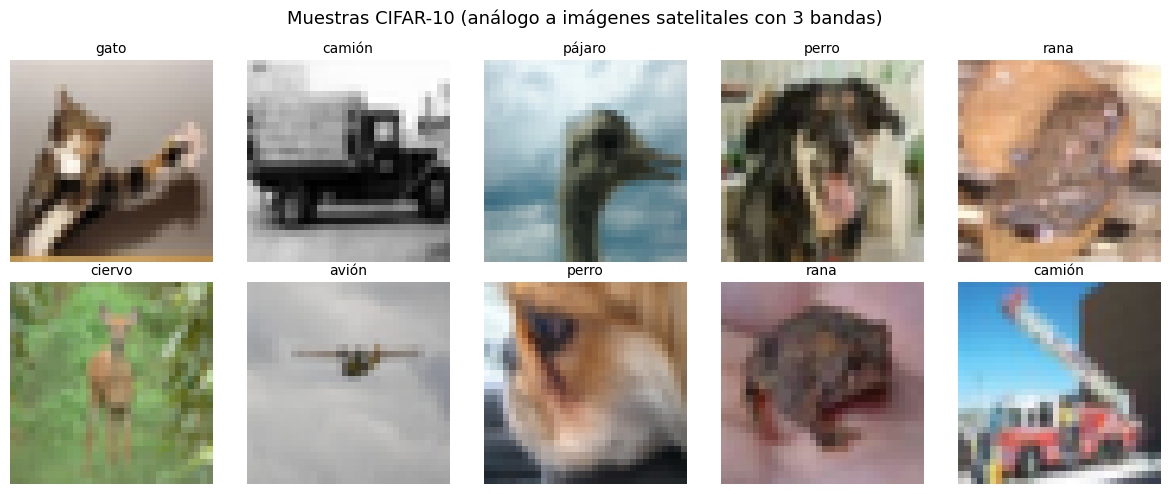

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Usar CIFAR-10 como sustituto de imágenes satelitales
# (misma CNN que usarías para parches Landsat/Sentinel)
(X_entrena, y_entrena), (X_prueba, y_prueba) = keras.datasets.cifar10.load_data()
X_entrena = X_entrena.astype('float32') / 255.0
X_prueba  = X_prueba.astype('float32') / 255.0
y_entrena = y_entrena.flatten()
y_prueba  = y_prueba.flatten()

nombres_cifar = ['avión','automóvil','pájaro','gato','ciervo',
                 'perro','rana','caballo','barco','camión']

print(f"Forma del tensor de entrenamiento: {X_entrena.shape}")
print(f"  = (60000 imágenes, 32×32 píxeles, 3 canales RGB)")

# Visualizar muestras
fig, ejes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(ejes.flat):
    idx = np.random.randint(len(X_entrena))
    ax.imshow(X_entrena[idx])
    ax.set_title(nombres_cifar[y_entrena[idx]], fontsize=10)
    ax.axis('off')
plt.suptitle('Muestras CIFAR-10 (análogo a imágenes satelitales con 3 bandas)', fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
# Definir la CNN (patrón encoder-decoder)
modelo_cnn = keras.Sequential([
    # === ENCODER: extracción de características ===
    # Bloque 1: detectar patrones de bajo nivel
    layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),      # 32×32 → 16×16
    layers.Dropout(0.25),

    # Bloque 2: detectar patrones de nivel medio
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),      # 16×16 → 8×8
    layers.Dropout(0.25),

    # === DECODER: clasificación ===
    layers.Flatten(),                  # 8×8×64 → vector de 4096
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')  # 10 probabilidades de clase
])

modelo_cnn.summary()

In [ ]:
# Compilar y entrenar
modelo_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

historial = modelo_cnn.fit(
    X_entrena, y_entrena,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

perdida_prueba, exactitud_prueba = modelo_cnn.evaluate(X_prueba, y_prueba, verbose=0)
print(f"\nExactitud en prueba: {exactitud_prueba:.2%}")

In [ ]:
# Curvas de aprendizaje
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

ejes[0].plot(historial.history['loss'], label='Pérdida entrenamiento')
ejes[0].plot(historial.history['val_loss'], label='Pérdida validación')
ejes[0].set_xlabel('Época'); ejes[0].set_ylabel('Pérdida')
ejes[0].set_title('Curva de Pérdida')
ejes[0].legend(); ejes[0].grid(alpha=0.3)

ejes[1].plot(historial.history['accuracy'], label='Exactitud entrenamiento')
ejes[1].plot(historial.history['val_accuracy'], label='Exactitud validación')
ejes[1].set_xlabel('Época'); ejes[1].set_ylabel('Exactitud')
ejes[1].set_title('Curva de Exactitud')
ejes[1].legend(); ejes[1].grid(alpha=0.3)

plt.suptitle('Progreso de Entrenamiento CNN – CIFAR-10', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(f"Con solo 10 épocas y arquitectura simple: ~70% de exactitud")
print("CNN más profundas entrenadas por más tiempo logran >90%")

## 7. CNN para Teledetección Peruana

La misma arquitectura CNN se aplica directamente a imágenes satelitales. Solo cambias la forma de entrada:

- **CIFAR-10:** `(32, 32, 3)` — 32×32 píxeles, 3 bandas RGB
- **Parche Landsat:** `(64, 64, 6)` — 64×64 píxeles, 6 bandas espectrales
- **Parche Sentinel-2:** `(64, 64, 13)` — 64×64 píxeles, 13 bandas

### Flujo de trabajo típico para clasificación de cobertura del suelo con CNN:

1. **Descargar parches de imágenes** desde GEE (Lab 6_1) para cada clase de cobertura
2. **Preprocesar:** Normalizar reflectancias al rango [0, 1]
3. **Dividir:** Entrenamiento/validación/prueba (evitar solapamiento espacial)
4. **Entrenar CNN** con early stopping
5. **Evaluar** con datos de prueba espacialmente independientes

### Ejemplo conceptual de código:

In [ ]:
# CNN para clasificación de cobertura del suelo con datos Landsat
# (ejemplo con datos sintéticos de la misma forma que datos reales)

# Simular parches de imágenes Landsat 32x32 con 6 bandas
np.random.seed(42)
n_por_clase = 200
tamano_patch = 32
n_bandas = 6

def crear_parche(firma_media, sigma, n):
    """Crear parches de imagen con firma espectral dada y variación espacial."""
    parches = []
    for _ in range(n):
        parche = np.random.normal(firma_media, sigma, (tamano_patch, tamano_patch, n_bandas))
        # Añadir estructura espacial simple
        for b in range(n_bandas):
            parche[:, :, b] += np.random.normal(0, sigma[b]*0.3, (tamano_patch, tamano_patch))
        parces.append(np.clip(parche, 0, 10000))
    return np.array(parces)

# Firmas espectrales de clases peruanas (reflectancia ×10000)
sigmas = np.array([200, 200, 200, 500, 400, 300])

parces_bosque   = crear_parche(np.array([400, 550, 350, 3800, 1600, 700]), sigmas, n_por_clase)
parces_cultivos = crear_parche(np.array([700, 800, 700, 2600, 2100, 1100]), sigmas, n_por_clase)
parces_agua     = crear_parche(np.array([700, 800, 600, 300, 150, 100]), sigmas//2, n_por_clase)
parces_urbano   = crear_parche(np.array([1200, 1300, 1400, 1700, 2400, 2100]), sigmas, n_por_clase)

X_parches = np.vstack([parces_bosque, parces_cultivos, parces_agua, parces_urbano])
X_parches = (X_parches / 10000.0).astype('float32')  # Normalizar a 0-1
y_parches = np.array([0]*n_por_clase + [1]*n_por_clase + [2]*n_por_clase + [3]*n_por_clase)

print(f"Parches de imagen: {X_parches.shape}  → (muestras, alto, ancho, bandas)")
print(f"Clases: Bosque(0), Cultivos(1), Agua(2), Urbano(3)")

# Dividir
from sklearn.model_selection import train_test_split
X_tr_p, X_te_p, y_tr_p, y_te_p = train_test_split(X_parches, y_parches, test_size=0.25, random_state=42)

# Definir CNN para 6 bandas Landsat
cnn_landsat = keras.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(tamano_patch, tamano_patch, n_bandas)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(4, activation='softmax')  # 4 clases de cobertura
])

cnn_landsat.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

hist_land = cnn_landsat.fit(X_tr_p, y_tr_p, epochs=15, batch_size=32,
                              validation_split=0.1, verbose=0)

_, acc_land = cnn_landsat.evaluate(X_te_p, y_te_p, verbose=0)
print(f"\nCNN Landsat – Exactitud de prueba: {acc_land:.2%}")

---
## 🔬 Ejercicio

1. Modifica la CNN de CIFAR-10 añadiendo un **tercer bloque convolucional** con 128 filtros antes del Flatten. ¿Mejora la exactitud de prueba?
2. ¿Por qué las CNN no necesitan `StandardScaler` mientras que las ANN densas sí?
3. En el contexto peruano, ¿qué tipo de datos de teledetección se beneficiarían más de las CNN vs. los métodos tabulares (RF/XGBoost)?

> **Pista:** Piensa en la diferencia entre *datos tabulares* (características ya extraídas) y *datos de imagen* (píxeles brutos). Las CNN son mejores para lo último porque aprenden a extraer características relevantes automáticamente.

In [ ]:
# Tu código aquí: añadir un tercer bloque convolucional
modelo_cnn_v2 = keras.Sequential([
    # Bloque 1
    layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(32,32,3)),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.25),
    # Bloque 2
    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.25),
    # --- Agregar Bloque 3 aquí ---
    # layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    # layers.Dropout(0.25),
    # ---
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

modelo_cnn_v2.summary()
print("\nDescomenta el Bloque 3 para explorar su efecto")

---
## Resumen

| Concepto | Conclusión clave |
|----------|------------------|
| Característica | Una propiedad medible de los datos; las CNN las aprenden automáticamente desde píxeles crudos |
| Tensor | Generalización de escalar/vector/matriz; las imágenes son tensores 3D |
| Aprendizaje de representaciones | Las redes profundas aprenden características automáticamente, sin ingeniería manual |
| Encoder-decoder | Comprimir entrada → representación compacta → producir salida (patrón universal) |
| Convolución | Filtro deslizante detecta patrones locales con pesos compartidos |
| Mapa de características | Salida de una capa convolucional; cada canal codifica un patrón diferente |
| Max Pooling | Reduce dimensiones espaciales; proporciona algo de invarianza a la translación |
| Jerarquía de características | Capas tempranas aprenden bordes; capas profundas aprenden objetos |
| Cuándo usar CNN | Datos de imágenes (parches satelitales, fotos de campo, imágenes de microscopio) |
| No usar CNN cuando | Datos tabulares — preferir RF/XGBoost |

### Aplicaciones CNN en Monitoreo Ambiental Peruano

| Aplicación | Datos de entrada | Salida |
|------------|-----------------|--------|
| Detección de deforestación | Parches Landsat/Sentinel | Bosque / Deforestado / Degradado |
| Clasificación de cobertura | Parches multiespectrales | Tipo de cobertura |
| Conteo de árboles | Imágenes de drone | Número de copas |
| Identificación de especies | Fotos de trampas cámara | Especie de fauna |
| Detección de incendios | Series temporales MODIS | Área quemada |